<a href="https://colab.research.google.com/github/ritacute123/APPCHATBOT/blob/main/Copy_of_XAI_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries are ready.
All tools loaded
Abbreviated educational descriptions — NOT official ETS rubric wording
6: Outstanding
5: Strong
4: Adequate
3: Limited
2: Seriously flawed
1: Deficient
0: Unscorable
Note: Official GRE Analytical Writing includes half-point scores; this dictionary does not train the model.

CASE A — ORIGINAL ESSAY (our first writing sample)
PURPOSE: Establish an initial automatically generated model prediction.
Technology change many thing in our life, and today it is impossible live without it.
Student use internet for find information fast, but sometimes they not understand topic very deep
because they only read short answer. Before, people go library and spend more time reading books,
now many just copy from website. This make learning faster, but maybe not better.

Many young people is depend too much on phone. They check message all time, even when they must
study. When I was in school, teacher tell us not use phone in class, but many student still hide
it und

,Measured proxy /6
Syntactic variety (proxy),5.018
Discourse organization (proxy),3.600
Topical vocabulary (proxy),5.114
Grammar & mechanics (proxy),1.917
Style & expression (proxy),3.359



CASE A — ORIGINAL ESSAY: FIRST MODEL PREDICTION
Predicted illustrative score: 3.521 / 6
Text → measured proxies → Random Forest → synthetic score; not an official GRE score

SHAP EXPLANATION — CASE A (ORIGINAL ESSAY)
NOTE: SHAP 'baseline' means reference model prediction, NOT the original essay's score.
SHAP reference baseline: 3.029
Random Forest prediction: 3.521
Baseline + SHAP contributions: 3.521


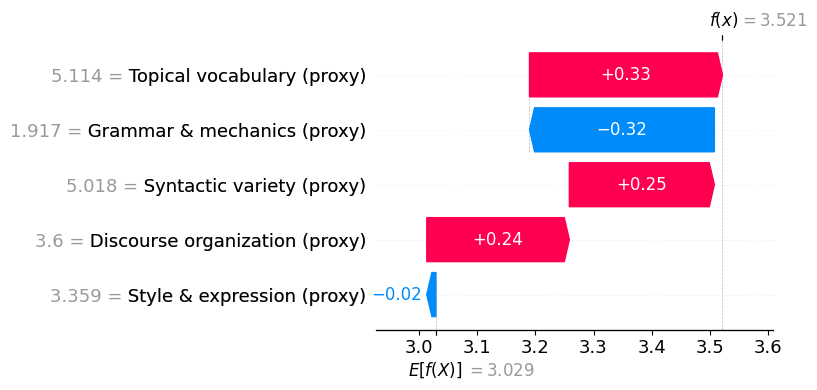


LIME EXPLANATION — CASE A (ORIGINAL ESSAY)
LIME explains the SAME model and the SAME original essay as SHAP.
Local approximation fit R²: 0.904



CASE B — REVISED ESSAY (a rewritten version of CASE A)
PURPOSE: Does the SAME model respond when the ACTUAL ESSAY TEXT changes?
No manual feature ratings have been changed.
CASE A original essay prediction: 3.521 / 6
CASE B revised essay prediction:  4.726 / 6
Change (B minus A): 1.204
Below: automatic feature measurements for each essay. The model is unchanged.


,Original,Revised text
Syntactic variety (proxy),5.018,3.824
Discourse organization (proxy),3.600,6.000
Topical vocabulary (proxy),5.114,6.000
Grammar & mechanics (proxy),1.917,5.500
Style & expression (proxy),3.359,6.000


SHAP below explains CASE B — the REVISED essay, not CASE A.


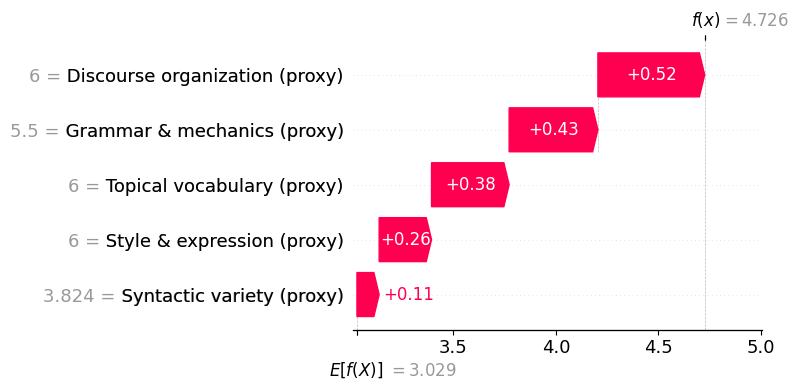


CASE C — WEAK ESSAY: FULL TEXT
Technology good. Phone good. School use phone. Many student use phone. Technology is good.
Phone is bad. Many phone. School is good but phone bad. People use computer. This good.
I think technology good. Very good. Sometimes bad. The end.

This text is automatically analyzed using the SAME model as Case A.

CASE C — SEPARATE DELIBERATELY WEAK ESSAY
PURPOSE: Contrast with CASE A. This is NOT a second scoring method or exam.
The same Python extraction and the SAME Random Forest model score both texts.
CASE A original essay prediction: 3.521 / 6
CASE C weak essay prediction:     1.634 / 6
Change (C minus A): -1.887
Below: the model's automatically extracted measurements for the two texts.


,Original,Weak
Syntactic variety (proxy),5.018,1.227
Discourse organization (proxy),3.600,0.643
Topical vocabulary (proxy),5.114,3.000
Grammar & mechanics (proxy),1.917,0.000
Style & expression (proxy),3.359,2.957


SHAP below explains CASE C — the WEAK essay, not CASE A.


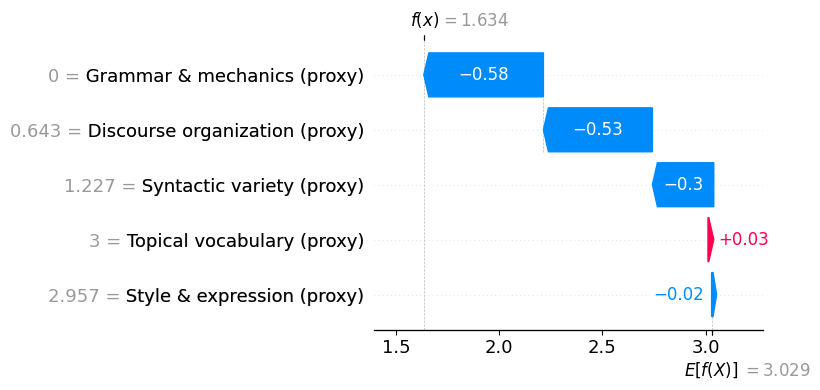


FINAL SUMMARY: all three rows are scored by the SAME Random Forest model


,Essay case,Why we use it,Illustrative RF score / 6
0,A: Original essay,Initial prediction,3.521
1,B: Revised original essay,Test sensitivity to revised text,4.726
2,C: Separate weak essay,Contrast with clearly weak text,1.634


SHAP/LIME explain model behavior, not correctness or fairness of scoring.


In [ ]:
# COTS 2026 — ONE-CELL AUTOMATED TEXT → RANDOM FOREST → SHAP → LIME
# Paste this entire file into ONE Google Colab CODE CELL and click Run once.
# No feature ratings are entered manually.
# Educational demonstration only: generated training labels, NOT validated GRE scoring.
# IMPORTANT: All three cases use THE SAME trained Random Forest model.
#   CASE A (ORIGINAL): First student essay; establishes the baseline CASE score.
#   CASE B (REVISED): Rewritten version of CASE A; tests model responsiveness to text.
#   CASE C (WEAK): Separate, intentionally weak example; tests how model responds to a contrast.
# Do not confuse CASE A score with the SHAP BASELINE. SHAP baseline is a model reference.
# No manual human feature ratings; Python extracts the same five proxy features for each case.

# ======================================================================
# STEP 01 — INSTALL LIBRARIES
# ======================================================================
# Install only if a library is missing; all inside this single cell.
import sys, subprocess, importlib.util
needed = [name for name in ("shap", "lime", "sklearn", "pandas", "numpy", "matplotlib") if importlib.util.find_spec(name) is None]
if needed:
    pip_names = ["scikit-learn" if name == "sklearn" else name for name in needed]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pip_names])
print("Libraries are ready.")


# ======================================================================
# STEP 02 — IMPORT TOOLS
# ======================================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
import shap
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display, HTML
SEED = 2026
print("All tools loaded")


# ======================================================================
# STEP 03 — DISPLAY GRE CONTEXT
# ======================================================================
rubric = {6:"Outstanding",5:"Strong",4:"Adequate",3:"Limited",2:"Seriously flawed",1:"Deficient",0:"Unscorable"}
print("Abbreviated educational descriptions — NOT official ETS rubric wording")
for level, description in rubric.items():
    print(f"{level}: {description}")
print("Note: Official GRE Analytical Writing includes half-point scores; this dictionary does not train the model.")


# ======================================================================
# STEP 04 — DISPLAY STUDENT ESSAY
# ======================================================================
ESSAY = 'Technology change many thing in our life, and today it is impossible live without it.\nStudent use internet for find information fast, but sometimes they not understand topic very deep\nbecause they only read short answer. Before, people go library and spend more time reading books,\nnow many just copy from website. This make learning faster, but maybe not better.\n\nMany young people is depend too much on phone. They check message all time, even when they must\nstudy. When I was in school, teacher tell us not use phone in class, but many student still hide\nit under desk. This habit reduce concentration and make it hard to finish task good.\n\nAlso technology change how we talk to each other. Some people prefer chat online instead of\nmeet face to face.'
print("\n" + "="*68)
print("CASE A — ORIGINAL ESSAY (our first writing sample)")
print("PURPOSE: Establish an initial automatically generated model prediction.")
print("="*68)
print(ESSAY)


# ======================================================================
# STEP 05 — EXTRACT TEXT FEATURES AUTOMATICALLY
# ======================================================================
FEATURES = ["Syntactic variety (proxy)", "Discourse organization (proxy)",
            "Topical vocabulary (proxy)", "Grammar & mechanics (proxy)",
            "Style & expression (proxy)"]

def extract_features(essay):
    words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", essay.lower())
    if not words:
        raise ValueError("Essay must contain words")
    sentences = [s.strip() for s in re.split(r'[.!?]+', essay) if s.strip()]
    sent_lens = [len(re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", s)) for s in sentences]
    connectors = re.findall(
        r'\b(?:however|therefore|although|because|for example|in addition|moreover|in conclusion|first|second|finally|on the other hand|but|also|instead)\b',
        essay.lower())
    content = [w for w in words if len(w) >= 5]
    flags = re.findall(
        r'\b(?:technology change|student use|student not|many thing|many student|people is|is depend|teacher tell|student still hide|this make|this habit reduce|good because good|not understand|for find|some time|sometime message|technology good|phone good|many phone|this good|phone bad|very good|technology is good|school use phone|school is good)\b',
        essay.lower())
    n = len(words)
    std = float(np.std(sent_lens)) if len(sent_lens) > 1 else 0
    variety = np.clip((std / 5.5) * 6, 0, 6)
    organization = np.clip(len(set(connectors)) / max(3, len(sentences)) * 9, 0, 6)
    topical = np.clip(len(set(content)) / n * 15, 0, 6)
    grammar = np.clip(5.5 - len(flags) / n * 43, 0, 6)
    avg_long = sum(len(w) >= 7 for w in words) / n
    style = np.clip(0.7 + avg_long * 14 + min(std, 8) * 0.14, 0, 6)
    return pd.DataFrame([[round(float(x), 3) for x in
                          [variety, organization, topical, grammar, style]]],
                        columns=FEATURES)

case = extract_features(ESSAY)
print("CASE A — Automatically extracted text measurements (NOT human ratings):")
display(case.T.rename(columns={0:"Measured proxy /6"}))


# ======================================================================
# STEP 06 — RANDOM FOREST PREDICTION
# ======================================================================
rng = np.random.default_rng(SEED)
X = pd.DataFrame(rng.uniform(0, 6, size=(1000, len(FEATURES))), columns=FEATURES)
TEACHING_WEIGHTS = np.array([0.17, 0.25, 0.20, 0.24, 0.14])
y = np.clip(X.to_numpy() @ TEACHING_WEIGHTS + rng.normal(0, 0.16, len(X)), 0, 6)
model = RandomForestRegressor(n_estimators=140, max_depth=9, min_samples_leaf=3,
                              random_state=SEED, n_jobs=-1)
model.fit(X, y)
prediction = float(model.predict(case)[0])
print("\nCASE A — ORIGINAL ESSAY: FIRST MODEL PREDICTION")
print(f"Predicted illustrative score: {prediction:.3f} / 6")
print("Text → measured proxies → Random Forest → synthetic score; not an official GRE score")


# ======================================================================
# STEP 07 — SHAP WATERFALL
# ======================================================================
shap_explainer = shap.TreeExplainer(model)
shap_result = shap_explainer(case)
print("\nSHAP EXPLANATION — CASE A (ORIGINAL ESSAY)")
print("NOTE: SHAP 'baseline' means reference model prediction, NOT the original essay's score.")
print(f"SHAP reference baseline: {float(shap_result.base_values[0]):.3f}")
print(f"Random Forest prediction: {prediction:.3f}")
print(f"Baseline + SHAP contributions: {float(shap_result.base_values[0] + shap_result.values[0].sum()):.3f}")
shap.plots.waterfall(shap_result[0], max_display=5, show=False)
plt.tight_layout(); plt.show()


# ======================================================================
# STEP 08 — LIME EXPLANATION
# ======================================================================
def predict_array(matrix):
    return model.predict(pd.DataFrame(matrix, columns=FEATURES))

lime_explainer = LimeTabularExplainer(X.to_numpy(), feature_names=FEATURES,
        mode="regression", discretize_continuous=False, random_state=SEED)
lime_result = lime_explainer.explain_instance(
        case.iloc[0].to_numpy(), predict_array, num_features=5, num_samples=1800)
print("\nLIME EXPLANATION — CASE A (ORIGINAL ESSAY)")
print("LIME explains the SAME model and the SAME original essay as SHAP.")
print(f"Local approximation fit R²: {lime_result.score:.3f}")
display(HTML(lime_result.as_html()))


# ======================================================================
# STEP 09 — REVISE ESSAY AND COMPARE
# ======================================================================
REVISED_ESSAY = 'Technology has changed how students learn, and its value depends on how carefully they use it.\nFor example, online libraries can help learners compare several sources before writing an argument.\nHowever, quick access does not guarantee deep understanding, because students may accept an answer without checking its evidence.\n\nIn addition, smartphones can distract students during lessons. Teachers can address this problem by setting clear expectations and guiding students toward purposeful research.\nAlthough digital tools create distractions, they can also support collaboration and access to information.\n\nIn conclusion, technology can improve education when students evaluate sources, reflect on their learning, and balance digital tools with discussion.'
revised_case = extract_features(REVISED_ESSAY)
revised_prediction = float(model.predict(revised_case)[0])
print("\n" + "="*68)
print("CASE B — REVISED ESSAY (a rewritten version of CASE A)")
print("PURPOSE: Does the SAME model respond when the ACTUAL ESSAY TEXT changes?")
print("No manual feature ratings have been changed.")
print("="*68)
print("CASE A original essay prediction:", round(prediction,3), "/ 6")
print("CASE B revised essay prediction: ", round(revised_prediction,3), "/ 6")
print("Change (B minus A):", round(revised_prediction-prediction,3))
print("Below: automatic feature measurements for each essay. The model is unchanged.")
display(pd.DataFrame({"Original":case.iloc[0], "Revised text":revised_case.iloc[0]}))
print("SHAP below explains CASE B — the REVISED essay, not CASE A.")
shap.plots.waterfall(shap_explainer(revised_case)[0], max_display=5, show=False)
plt.tight_layout();plt.show()


# ======================================================================
# STEP 10 — TEST WEAK ESSAY
# ======================================================================
WEAK_ESSAY = 'Technology good. Phone good. School use phone. Many student use phone. Technology is good.\nPhone is bad. Many phone. School is good but phone bad. People use computer. This good.\nI think technology good. Very good. Sometimes bad. The end.'
print("\n" + "="*68)
print("CASE C — WEAK ESSAY: FULL TEXT")
print("="*68)
print(WEAK_ESSAY)
print("\nThis text is automatically analyzed using the SAME model as Case A.")
weak_case=extract_features(WEAK_ESSAY)
weak_prediction=float(model.predict(weak_case)[0])
print("\n" + "="*68)
print("CASE C — SEPARATE DELIBERATELY WEAK ESSAY")
print("PURPOSE: Contrast with CASE A. This is NOT a second scoring method or exam.")
print("The same Python extraction and the SAME Random Forest model score both texts.")
print("="*68)
print("CASE A original essay prediction:", round(prediction,3), "/ 6")
print("CASE C weak essay prediction:    ", round(weak_prediction,3), "/ 6")
print("Change (C minus A):", round(weak_prediction-prediction,3))
print("Below: the model's automatically extracted measurements for the two texts.")
display(pd.DataFrame({"Original":case.iloc[0], "Weak":weak_case.iloc[0]}))
print("SHAP below explains CASE C — the WEAK essay, not CASE A.")
shap.plots.waterfall(shap_explainer(weak_case)[0],max_display=5,show=False)
plt.tight_layout();plt.show()


# ======================================================================
# FINAL SUMMARY — THREE CASES / ONE MODEL / NO MANUAL RATINGS
# ======================================================================
summary = pd.DataFrame({
    "Essay case": ["A: Original essay", "B: Revised original essay", "C: Separate weak essay"],
    "Why we use it": ["Initial prediction", "Test sensitivity to revised text", "Contrast with clearly weak text"],
    "Illustrative RF score / 6": [prediction, revised_prediction, weak_prediction]
})
summary["Illustrative RF score / 6"] = summary["Illustrative RF score / 6"].round(3)
print("\nFINAL SUMMARY: all three rows are scored by the SAME Random Forest model")
display(summary)
print("WARNING: Synthetic training labels; these are not GRE grades or validated writing evaluations.")
print("SHAP/LIME explain model behavior, not correctness or fairness of scoring.")
